# Threshold Exploration: Number of Cell types deviating in Query from Reference mixing score distribution

**Step 2a** of MapQC pipeline:\
For each cell type present in the query, we compare (via the Kolmogorov-Smirnov-test) the distribution of **healthy** query sample mixing scores to the reference distribution. If the distribution of healthy query samples is significantly lower (after multiple testing correction), we consider the mapping unsucessful in that particular cell type.\
In this notebook we explore a way to establish a sensible threshold for the number of cell types that are considered unsucessfully mapped, before declaring the dataset as unsucessfully mapped as a whole. For that we use the datasets of the curated HCLA reference atlas to explore the usual/expected numbers of "deviating" cell types in a dataset, assuming no resiudal batch effect is present.\
For that, we test mixing score distribution in each cell type present in a dataset against mixing score of all the other datasets in the reference. Thus the  After that the p-values of that dataset are multiple testing corrected and the number of cell types that scores $p < 0.05$ are counted to eastablish a number/fraction that can be expected given the best possible integration of healthy datasets.






### Imports

In [7]:
import warnings
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scipy
import pandas as pd
import json
import seaborn as sb
import os
from os.path import abspath
from numpy import ndarray
from typing import IO, Dict, List, Literal, Optional, Tuple, Union
import statsmodels.stats.multitest as mtc

<IPython.core.display.Javascript object>

In [8]:
%load_ext nb_black

The nb_black extension is already loaded. To reload it, use:
  %reload_ext nb_black


<IPython.core.display.Javascript object>

### Set parameters

In [9]:
sb.set(rc={"figure.figsize": (11.7, 8.27)})  # set smaller after review

<IPython.core.display.Javascript object>

In [10]:
# Set global seed
np.random.seed(42)

# Ignore warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# Set directories
DATA_DIR = abspath(os.path.join(os.getcwd(), os.pardir, "dataset_examples", "data"))
OUT_DIR = abspath(os.path.join(os.getcwd(), os.pardir, "dataset_examples", "out"))

<IPython.core.display.Javascript object>

### Data loading 

In [14]:
adata = sc.read(f"{DATA_DIR}/HLCA_full_tranf.h5ad")

<IPython.core.display.Javascript object>

In [15]:
# subsample adata to reference
adata = adata[adata.obs.query_or_reference == "reference"].copy()

<IPython.core.display.Javascript object>

In [24]:
# load baseline scores
baseline = pd.read_csv(f"{OUT_DIR}/baseline_HLCA.csv", index_col="Unnamed: 0")

<IPython.core.display.Javascript object>

### Data preprocessing
Here we add baseline scores to the reference adata.obs, the baseline scores are aggregated by sample and cell type and corrected for sample size using a precaluted log-linear transformation model. 

In [25]:
adata.obs["raw_score"] = baseline

<IPython.core.display.Javascript object>

In [26]:
# aggregating data by sample and cell type
group_baseline = (
    adata.obs.groupby(["cell_label", "sample"])
    .agg({"raw_score": "mean", "dataset": "first", "study": "count"})
    .dropna(inplace=False)
    .reset_index(drop=False)
    .rename(columns={"study": "count"})
)

<IPython.core.display.Javascript object>

In [27]:
del adata

<IPython.core.display.Javascript object>

In [28]:
group_baseline.cell_label.cat.remove_unused_categories(inplace=True)

<IPython.core.display.Javascript object>

In [29]:
# adding log-sample size for the correction function
group_baseline["log_count"] = np.log(group_baseline["count"])

<IPython.core.display.Javascript object>

In [30]:
group_baseline

,cell_label,sample,raw_score,dataset,count,log_count
0,AT2,356C_0h,0.452104,Meyer_2019,378,5.934894
1,AT2,356C_12h,0.495479,Meyer_2019,353,5.866468
2,AT2,356C_24h,0.434208,Meyer_2019,572,6.349139
3,AT2,356C_72h,0.659783,Meyer_2019,171,5.141664
4,AT2,368C_12h,0.420278,Meyer_2019,52,3.951244
...,...,...,...,...,...,...
1142,Transitional Club-AT2,distal 1a,0.427365,Krasnow_2020,168,5.123964
1143,Transitional Club-AT2,distal 2,0.242617,Krasnow_2020,331,5.802118
1144,Transitional Club-AT2,distal 3,0.411119,Krasnow_2020,358,5.880533
1145,Transitional Club-AT2,medial 2,0.409729,Krasnow_2020,136,4.912655


<IPython.core.display.Javascript object>

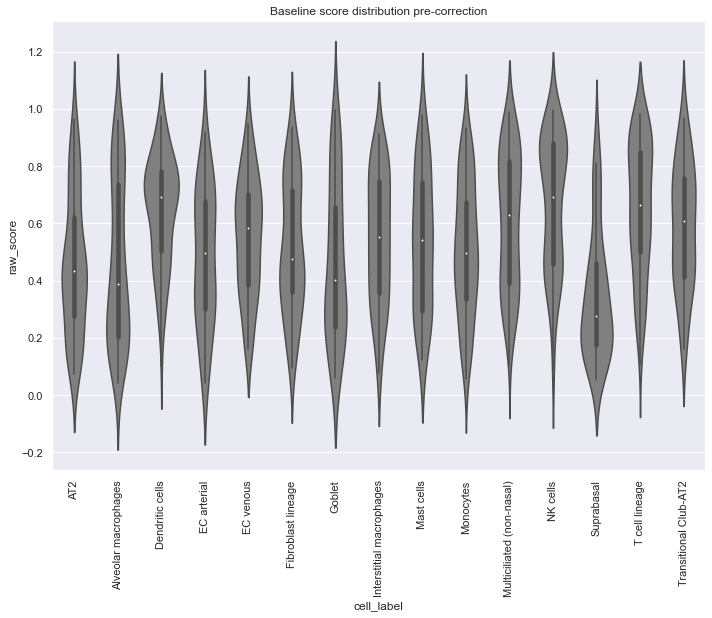

<IPython.core.display.Javascript object>

In [31]:
sb.violinplot(data=group_baseline, x="cell_label", y="raw_score", color="gray")
plt.title("Baseline score distribution pre-correction")
plt.xticks(rotation=90)
plt.show()

In [32]:
# transform
transformation = pd.read_csv(f"{OUT_DIR}/transformation_HLCA.csv")

<IPython.core.display.Javascript object>

In [33]:
# performing correction by sample size
group_baseline["corr_score"] = np.nan
for ct in transformation.cell_label:
    scores_old = group_baseline.loc[group_baseline.cell_label == ct, "raw_score"]
    sample_sizes = group_baseline.loc[group_baseline.cell_label == ct, "log_count"]
    slope = transformation.loc[transformation.cell_label == ct, "slope"].item()
    intercept = transformation.loc[transformation.cell_label == ct, "intercept"].item()
    group_baseline.loc[group_baseline.cell_label == ct, "corr_score"] = scores_old - (
        slope * sample_sizes + intercept
    )

<IPython.core.display.Javascript object>

In [34]:
group_baseline["corr_score"]

0       0.023229
1       0.059002
2       0.051358
3       0.142776
4      -0.228990
          ...   
1142   -0.017138
1143   -0.093728
1144    0.087280
1145   -0.068475
1146    0.019063
Name: corr_score, Length: 1147, dtype: float64

<IPython.core.display.Javascript object>

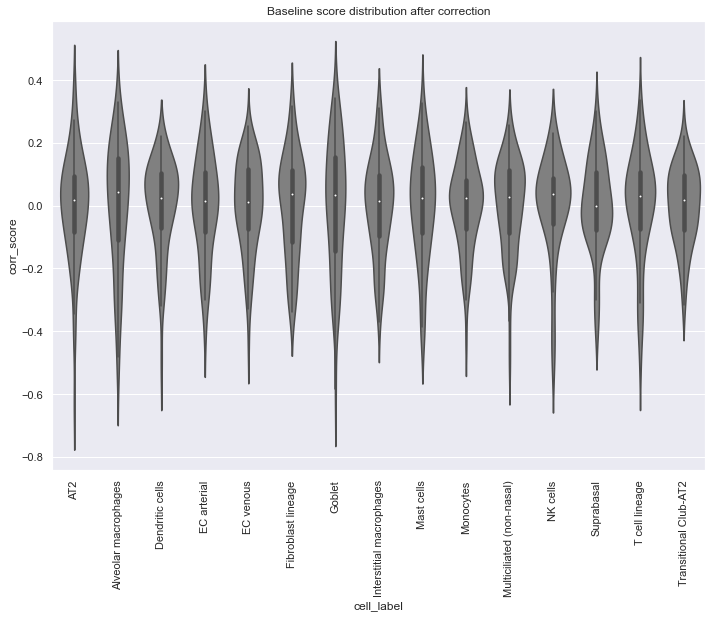

<IPython.core.display.Javascript object>

In [35]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
plt.title("Baseline score distribution after correction")
plt.xticks(rotation=90)
plt.show()

In [36]:
group_baseline.dataset.cat.categories

Index(['Banovich_Kropski_2020', 'Barbry_Leroy_2020',
       'Jain_Misharin_2021_10Xv1', 'Jain_Misharin_2021_10Xv2', 'Krasnow_2020',
       'Lafyatis_Rojas_2019_10Xv1', 'Lafyatis_Rojas_2019_10Xv2', 'Meyer_2019',
       'Misharin_2021', 'Misharin_Budinger_2018', 'Nawijn_2021',
       'Seibold_2020_10Xv2', 'Seibold_2020_10Xv3', 'Teichmann_Meyer_2019'],
      dtype='object')

<IPython.core.display.Javascript object>

### Testing distribution difference for each dataset in the reference in cell types represented + multiple testing correction

**Note: only cell types represented by at least three samples are considered**

In [78]:
p = 0.05

<IPython.core.display.Javascript object>

In [79]:
def perform_one_sided_ks_test(
    query_scores: ndarray, reference_scores: ndarray
) -> Union[ndarray, None]:
    if min(len(query_scores), len(reference_scores)) > 0:
        pvalues = scipy.stats.ks_2samp(
            reference_scores, query_scores, alternative="less"
        ).pvalue
        return pvalues
    return None


def multiple_testing_correction(tested_cell_types: pd.DataFrame) -> pd.DataFrame:
    tested_cell_types["pvals_corr"] = mtc.multipletests(
        tested_cell_types["pvalue"], p, "fdr_bh"
    )[1]

    return tested_cell_types

<IPython.core.display.Javascript object>

In [82]:
numbers_rejected = []
pvalues_all = []
for ds in group_baseline.dataset.cat.categories:
    pvals = []
    for ct in group_baseline.cell_label.cat.categories:
        scores_ds = group_baseline[
            (group_baseline.dataset == ds) & (group_baseline.cell_label == ct)
        ].corr_score
        scores_ref = group_baseline[
            ~(group_baseline.dataset == ds) & (group_baseline.cell_label == ct)
        ].corr_score

        if len(scores_ds) >= 3:
            ks_pval = perform_one_sided_ks_test(scores_ds, scores_ref)
            pvals.append((ct, ks_pval))

    tested_cell_types = pd.DataFrame(data=pvals, columns=["cell_label", "pvalue"])

    tested_cell_types = multiple_testing_correction(tested_cell_types)

    pvalues_all.extend(
        list(tested_cell_types[["cell_label", "pvals_corr"]].itertuples(index=False))
    )

    rejected = tested_cell_types[tested_cell_types.pvals_corr < p]

    if len(rejected) > 0:
        print(ds)
        print(rejected)
        print()
    numbers_rejected.append((ds, len(rejected), len(tested_cell_types)))

numbers_rejected = pd.DataFrame(
    data=numbers_rejected, columns=["dataset", "n_rejected", "n_all"]
)
pvalues_all = pd.DataFrame(data=pvalues_all, columns=["cell_label", "pvalue"])

Banovich_Kropski_2020
   cell_label   pvalue  pvals_corr
10   NK cells  0.00158    0.022116

Barbry_Leroy_2020
                  cell_label    pvalue  pvals_corr
0       Alveolar macrophages  0.006712    0.013423
1            Dendritic cells  0.015925    0.026542
2                  EC venous  0.006050    0.013423
4                     Goblet  0.000058    0.000291
6                 Mast cells  0.000055    0.000291
7  Multiciliated (non-nasal)  0.036930    0.046163
8                 Suprabasal  0.001134    0.003781
9             T cell lineage  0.028259    0.040370

Krasnow_2020
    cell_label    pvalue  pvals_corr
11  Suprabasal  0.001915     0.02681

Teichmann_Meyer_2019
                  cell_label    pvalue  pvals_corr
0                        AT2  0.000458    0.001374
1       Alveolar macrophages  0.014638    0.021957
2            Dendritic cells  0.013675    0.021957
4         Fibroblast lineage  0.000206    0.000927
7  Multiciliated (non-nasal)  0.011964    0.021957
8             

<IPython.core.display.Javascript object>

In [83]:
# collection of all corrected p-values generated in the process
pvalues_all

,cell_label,pvalue
0,AT2,0.863285
1,Alveolar macrophages,0.945779
2,Dendritic cells,0.863285
3,EC arterial,0.454581
4,EC venous,0.863285
...,...,...
116,Fibroblast lineage,0.000927
117,Interstitial macrophages,0.111273
118,Monocytes,0.052904
119,Multiciliated (non-nasal),0.021957


<IPython.core.display.Javascript object>

In [84]:
numbers_rejected["fraction"] = (
    numbers_rejected["n_rejected"] / numbers_rejected["n_all"]
)

<IPython.core.display.Javascript object>

In [85]:
# numbers and fractions of all cell types with corr. p-values below 0.05 by dataset
numbers_rejected

,dataset,n_rejected,n_all,fraction
0,Banovich_Kropski_2020,1,14,0.071429
1,Barbry_Leroy_2020,8,10,0.800000
2,Jain_Misharin_2021_10Xv1,0,3,0.000000
3,Jain_Misharin_2021_10Xv2,0,5,0.000000
4,Krasnow_2020,1,14,0.071429
5,Lafyatis_Rojas_2019_10Xv1,0,4,0.000000
6,Lafyatis_Rojas_2019_10Xv2,0,13,0.000000
7,Meyer_2019,0,12,0.000000
8,Misharin_2021,0,9,0.000000
9,Misharin_Budinger_2018,0,11,0.000000


<IPython.core.display.Javascript object>

Most datasets exhibit no cell types significantly deviating from the reference distribution. The datasets **Banovich_Kropski_2020** and **Krasnow_2020** exhibit one cell type below the reference distribution at almost a full cell type set represented (14/15). Two datasets exhibit unusual behavior: **Barbry_Leroy_2020** possibly due to being nasal samples and **Teichmann_Meyer_2019** for yet unestablished reason. Based on these numbers a threshold of either 0 or < 10% (which would effectively be 0 for less than 10 cell types and 1 for more than 10 cell types represented) seems reasonable. 	

### Some plots to visualize the results

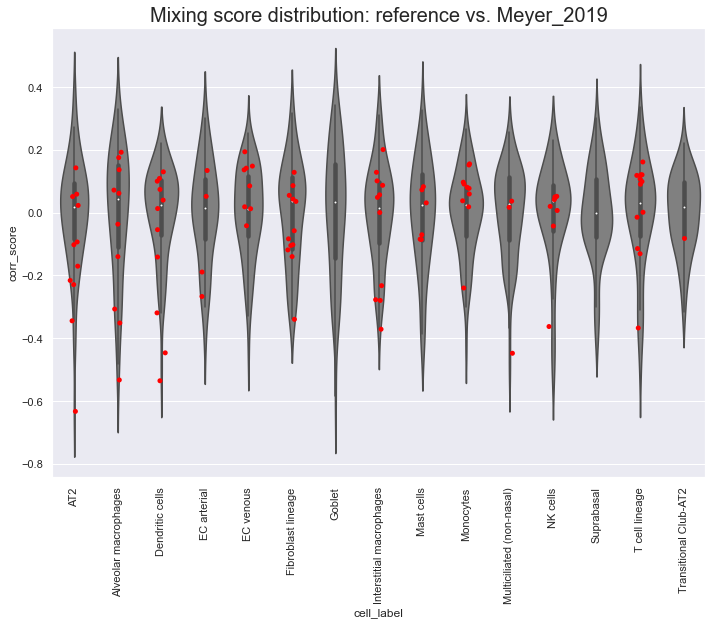

<IPython.core.display.Javascript object>

In [86]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
sb.stripplot(
    data=group_baseline[group_baseline.dataset == "Meyer_2019"],
    x="cell_label",
    y="corr_score",
    color="red",
)
plt.title("Mixing score distribution: reference vs. Meyer_2019", fontsize=20)
plt.xticks(rotation=90)
plt.show()

Positive example **Meyer_2019**: No outlier cell types but outliers within the distributions, not enough to reach significance in KS-test.

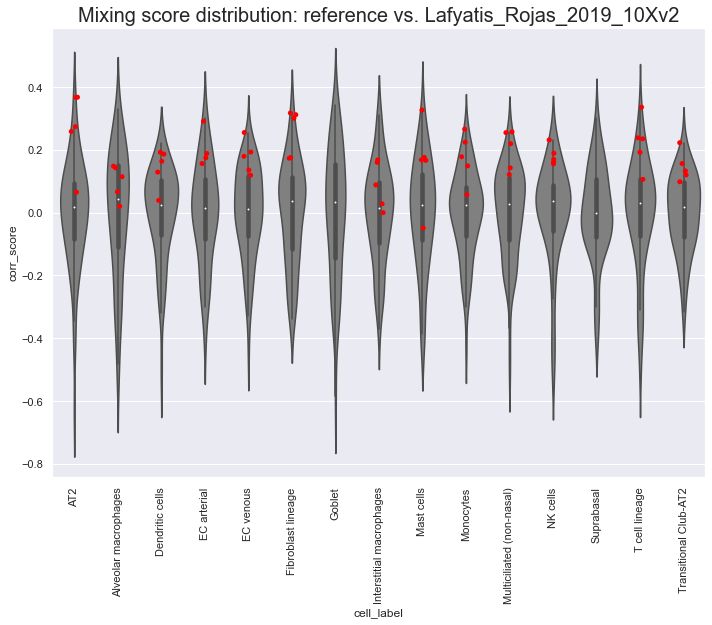

<IPython.core.display.Javascript object>

In [87]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
sb.stripplot(
    data=group_baseline[group_baseline.dataset == "Lafyatis_Rojas_2019_10Xv2"],
    x="cell_label",
    y="corr_score",
    color="red",
)
plt.title(
    "Mixing score distribution: reference vs. Lafyatis_Rojas_2019_10Xv2", fontsize=20
)
plt.xticks(rotation=90)
plt.show()

**Lafyatis_Rojas_2019_10Xv2**: No failed cell types but consistently on top of distribution. Take into account or ignore?

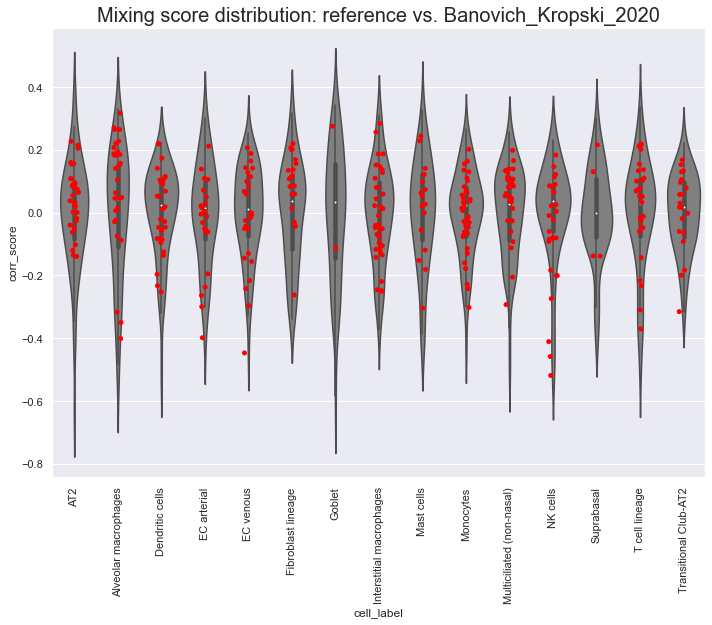

<IPython.core.display.Javascript object>

In [88]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
sb.stripplot(
    data=group_baseline[group_baseline.dataset == "Banovich_Kropski_2020"],
    x="cell_label",
    y="corr_score",
    color="red",
)
plt.title("Mixing score distribution: reference vs. Banovich_Kropski_2020", fontsize=20)
plt.xticks(rotation=90)
plt.show()

In the dataset **Banovich_Kropski_2020** only the NK cells fall below the reference distribution with a p-value of 0.02. While significant, most samples fall within the distribution with few extreme outliers.\
**Bonus observation**: 3-4 outlier samples in Macrophages, Endothelial cells, Dendritic and NK cells. Maybe different sampling method?

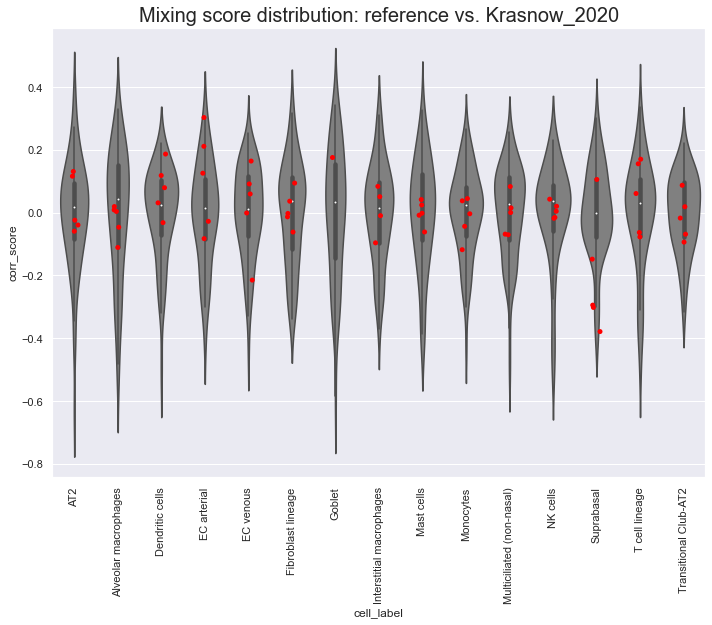

<IPython.core.display.Javascript object>

In [89]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
sb.stripplot(
    data=group_baseline[group_baseline.dataset == "Krasnow_2020"],
    x="cell_label",
    y="corr_score",
    color="red",
)
plt.title("Mixing score distribution: reference vs. Krasnow_2020", fontsize=20)
plt.xticks(rotation=90)
plt.show()

The only outlier cell type in **Krasnow_2020** are Suprabasal cells with a p-value of 0.028. All other cell types represented seem to be well within the norm. This dataset should not neccesary be rejected.\
**Idea**: Accept a lowly significant deviating cell type but not highly significnat e.g below 0.01

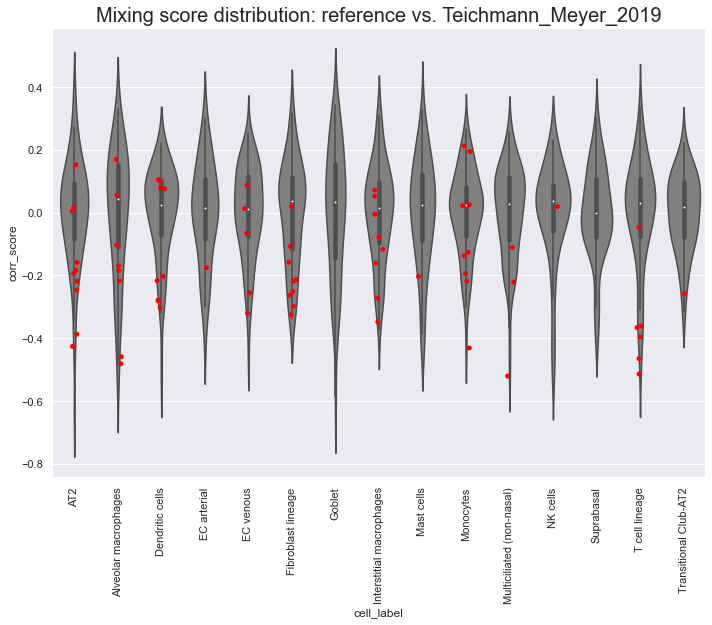

<IPython.core.display.Javascript object>

In [90]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
sb.stripplot(
    data=group_baseline[group_baseline.dataset == "Teichmann_Meyer_2019"],
    x="cell_label",
    y="corr_score",
    color="red",
)
plt.title("Mixing score distribution: reference vs. Teichmann_Meyer_2019", fontsize=20)
plt.xticks(rotation=90)
plt.show()

For yet unknown reasons, the **Teichman_Meyer_2019** dataset exhibits lower than expected mixing scores in 6/9 represented cell types with 3 highly significant (< 0.01) cell types. This is a definite outlier and should be investigated.

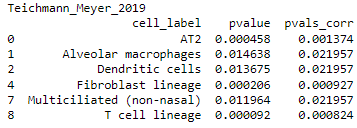



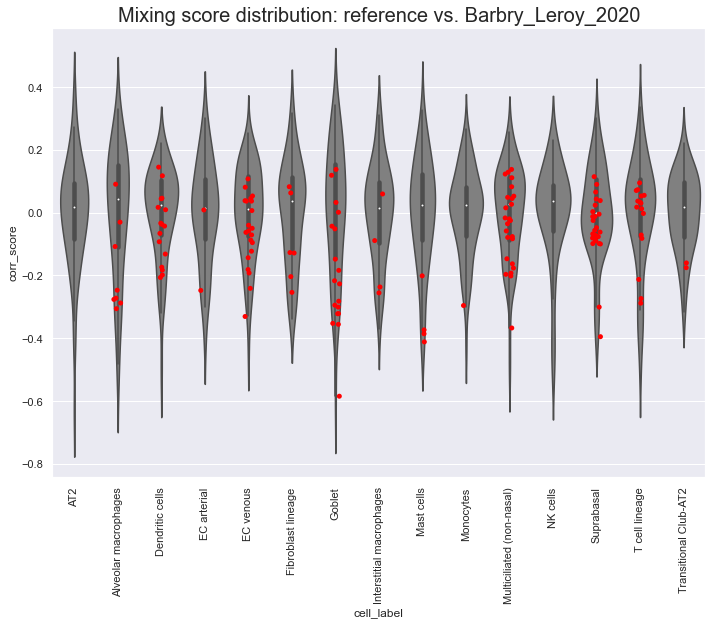

<IPython.core.display.Javascript object>

In [91]:
sb.violinplot(data=group_baseline, x="cell_label", y="corr_score", color="gray")
sb.stripplot(
    data=group_baseline[group_baseline.dataset == "Barbry_Leroy_2020"],
    x="cell_label",
    y="corr_score",
    color="red",
)
plt.title("Mixing score distribution: reference vs. Barbry_Leroy_2020", fontsize=20)
plt.xticks(rotation=90)
plt.show()

The **Barbry_Leroy_2020** dataset mixing scores also consistently fall below the reference, possibly due to being a nasaly-sampled dataset in contrary to donor lungs.
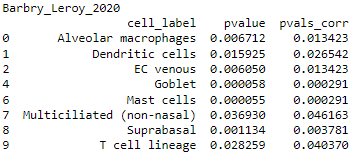


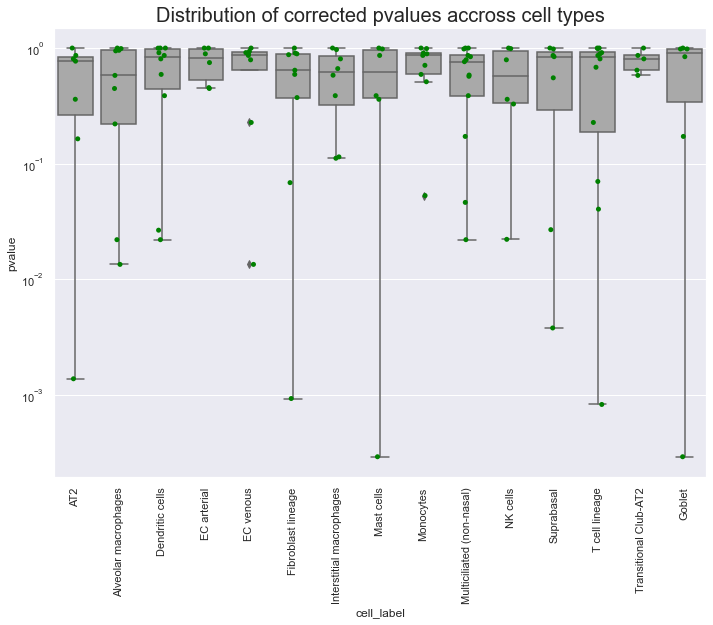

<IPython.core.display.Javascript object>

In [92]:
sb.boxplot(data=pvalues_all, x="cell_label", y="pvalue", color="darkgray")
sb.stripplot(data=pvalues_all, x="cell_label", y="pvalue", color="green")
plt.title("Distribution of corrected pvalues accross cell types", fontsize=20)
plt.xticks(rotation=90)
plt.yscale("log")
plt.show()

### Summary

The threshold should be either 0, 1 or 10%.\
Possible adjustments to a threshold of 1 or 10%:
- Take number of samples representing that cell type into account.
- Take the p-value of cell type into account: more or less significant
- Take p-value distribution of reference into account: is that cell type maybe more variable in p-values (T-cells vs Endothelial cells)?
